In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [29]:
df = pd.read_csv("../data/raw/student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [31]:
# Create target variable
# 1 = Pass, 0 = Fail

df["pass"] = (df["G3"] >= 10).astype(int)

print("Pass/Fail target created successfully!")

print(df[["G3", "pass"]].head())

Pass/Fail target created successfully!
   G3  pass
0   6     0
1   6     0
2  10     1
3  15     1
4  10     1


In [33]:
print("Pass/Fail distribution:")
print(df["pass"].value_counts())

print("\nPercentage distribution:")
print(df["pass"].value_counts(normalize=True) * 100)

Pass/Fail distribution:
pass
1    265
0    130
Name: count, dtype: int64

Percentage distribution:
pass
1    67.088608
0    32.911392
Name: proportion, dtype: float64


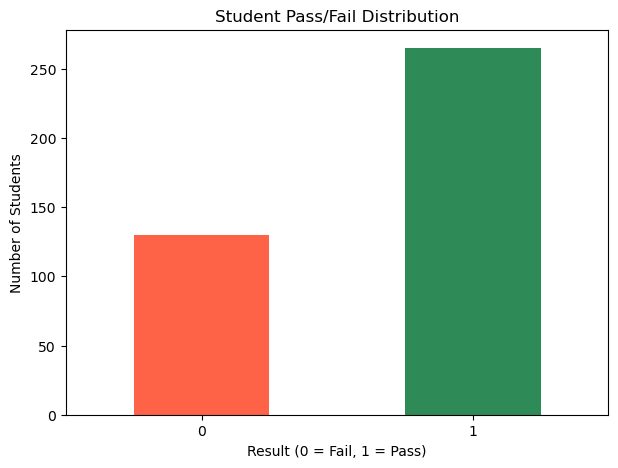

In [35]:
plt.figure(figsize=(7, 5))

df["pass"].value_counts().sort_index().plot(
    kind="bar",
    color=["tomato", "seagreen"]
)

plt.title("Student Pass/Fail Distribution")
plt.xlabel("Result (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.show()

In [37]:
# Remove G3 because it is the final grade we want to predict.
# Remove pass because it is our target variable.

X = df.drop(columns=["G3", "pass"])

# Target variable
y = df["pass"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

Input features shape: (395, 32)
Target shape: (395,)

Input features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (316, 32)
Testing data shape: (79, 32)

Training target distribution:
pass
1    212
0    104
Name: count, dtype: int64

Testing target distribution:
pass
1    53
0    26
Name: count, dtype: int64


In [10]:
categorical_columns = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    exclude=["object", "str", "category"]
).columns.tolist()

print("Categorical columns:", len(categorical_columns))
print("Numerical columns:", len(numerical_columns))

print("\nCategorical features:")
print(categorical_columns)

print("\nNumerical features:")
print(numerical_columns)

Categorical columns: 17
Numerical columns: 15

Categorical features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [45]:
# Identify categorical and numerical columns

categorical_columns = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical columns:", len(categorical_columns))
print("Numerical columns:", len(numerical_columns))

print("\nCategorical features:")
print(categorical_columns)

print("\nNumerical features:")
print(numerical_columns)

Categorical columns: 17
Numerical columns: 15

Categorical features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [47]:
# STEP: Identify categorical and numerical columns

categorical_columns = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical columns:", len(categorical_columns))
print("Numerical columns:", len(numerical_columns))


# STEP: Create preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ],
    sparse_threshold=0
)

# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing completed successfully!")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Categorical columns: 17
Numerical columns: 15

Preprocessing completed successfully!
Processed training shape: (316, 58)
Processed testing shape: (79, 58)


In [49]:
print("========== FINAL DATASET SUMMARY ==========")

print("Original dataset:", df.shape)

print("Training samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])

print("Number of model features:", X_train_processed.shape[1])

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nMissing values in original dataset:", df.isnull().sum().sum())

print("\nPreprocessing pipeline completed successfully!")



========== FINAL DATASET SUMMARY ==========
Original dataset: (395, 34)
Training samples: 316
Testing samples: 79
Number of model features: 58

Training labels: (316,)
Testing labels: (79,)

Missing values in original dataset: 0

Preprocessing pipeline completed successfully!


In [51]:
import os
import numpy as np

# Create processed data folder if it doesn't exist
os.makedirs("../data/processed", exist_ok=True)

# Save training and testing data
np.savez_compressed(
    "../data/processed/student_data.npz",
    X_train=X_train_processed,
    X_test=X_test_processed,
    y_train=y_train,
    y_test=y_test
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!
